## Document findings on robustness testing by generating a structured technical report, detailing experimental setups, performance trends, failure modes, and recommendations for improving model resilience.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

In [2]:
df = pd.read_csv("heart.csv")
df = df.drop_duplicates().dropna().reset_index(drop=True)

print("Dataset Shape:", df.shape)
print("Features:", df.shape[1] - 1)
print("Total Samples:", len(df))

print("\nClass Distribution:")
print(df["target"].value_counts())

Dataset Shape: (302, 14)
Features: 13
Total Samples: 302

Class Distribution:
target
1    164
0    138
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X = df.drop(columns=["target"])
y = df["target"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

baseline = {
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, zero_division=0),
    "Recall": recall_score(y_test, predictions, zero_division=0),
    "F1 Score": f1_score(y_test, predictions, zero_division=0)
}

display(pd.DataFrame([baseline]).round(4))

,Accuracy,Precision,Recall,F1 Score
0,0.7869,0.75,0.9091,0.8219


In [4]:
robustness_findings = pd.DataFrame({
    "Testing Area": [
        "Train-Test Stability",
        "False Positive and False Negative Analysis",
        "Model Bias and Fairness",
        "Bias Mitigation",
        "Adversarial Testing",
        "Out-of-Distribution Testing",
        "Cross-Validation"
    ],
    "Purpose": [
        "Check performance across different data splits",
        "Identify incorrect model predictions",
        "Check fairness across demographic groups",
        "Evaluate methods to reduce prediction bias",
        "Test sensitivity to modified input features",
        "Analyze behavior on unfamiliar synthetic samples",
        "Measure performance consistency across folds"
    ],
    "Evaluation": [
        "Accuracy and standard deviation",
        "Confusion matrix and error patterns",
        "Disparate impact and equalized odds",
        "Accuracy and fairness metric comparison",
        "Prediction flip rate and accuracy change",
        "Confidence and prediction distribution",
        "Mean accuracy and accuracy variance"
    ]
})

display(robustness_findings)

,Testing Area,Purpose,Evaluation
0,Train-Test Stability,Check performance across different data splits,Accuracy and standard deviation
1,False Positive and False Negative Analysis,Identify incorrect model predictions,Confusion matrix and error patterns
2,Model Bias and Fairness,Check fairness across demographic groups,Disparate impact and equalized odds
3,Bias Mitigation,Evaluate methods to reduce prediction bias,Accuracy and fairness metric comparison
4,Adversarial Testing,Test sensitivity to modified input features,Prediction flip rate and accuracy change
5,Out-of-Distribution Testing,Analyze behavior on unfamiliar synthetic samples,Confidence and prediction distribution
6,Cross-Validation,Measure performance consistency across folds,Mean accuracy and accuracy variance


In [5]:
continuous_features = [
    col for col in ["age", "trestbps", "chol", "thalach", "oldpeak"]
    if col in X_test.columns
]

X_perturbed = X_test.copy()
rng = np.random.default_rng(42)

for col in continuous_features:
    change = 0.05 * X_train[col].std()
    direction = rng.choice([-1, 1], size=len(X_test))

    X_perturbed[col] = (
        X_test[col].to_numpy() + direction * change
    ).clip(X_train[col].min(), X_train[col].max())

    if col != "oldpeak":
        X_perturbed[col] = X_perturbed[col].round()

perturbed_predictions = model.predict(X_perturbed)

adversarial_accuracy = accuracy_score(y_test, perturbed_predictions)
prediction_flip_rate = np.mean(predictions != perturbed_predictions)

print("Original Accuracy:", round(baseline["Accuracy"], 4))
print("Perturbed Accuracy:", round(adversarial_accuracy, 4))
print("Prediction Flip Rate:", round(prediction_flip_rate, 4))

Original Accuracy: 0.7869
Perturbed Accuracy: 0.7869
Prediction Flip Rate: 0.0


In [6]:
ood_samples = X_test.copy()

for col in continuous_features:
    col_range = X_train[col].max() - X_train[col].min()

    direction = rng.choice([-1, 1], size=len(ood_samples))

    ood_samples[col] = (
        ood_samples[col].to_numpy() +
        direction * 0.25 * col_range
    )

    ood_samples[col] = ood_samples[col].clip(
        X_train[col].min() - 0.25 * col_range,
        X_train[col].max() + 0.25 * col_range
    )

ood_probabilities = model.predict_proba(ood_samples)
normal_probabilities = model.predict_proba(X_test)

normal_confidence = normal_probabilities.max(axis=1)
ood_confidence = ood_probabilities.max(axis=1)

print("Normal Mean Confidence:", round(normal_confidence.mean(), 4))
print("OOD Mean Confidence:", round(ood_confidence.mean(), 4))
print("High Confidence OOD Samples:", int((ood_confidence >= 0.90).sum()))

Normal Mean Confidence: 0.7692
OOD Mean Confidence: 0.6962
High Confidence OOD Samples: 6


In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_results = []

for folds in [3, 5, 10]:
    skf = StratifiedKFold(
        n_splits=folds,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        RandomForestClassifier(n_estimators=100, random_state=42),
        X,
        y,
        cv=skf,
        scoring="accuracy"
    )

    cv_results.append({
        "Folds": folds,
        "Mean Accuracy": scores.mean(),
        "Accuracy Variance": scores.var(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df.round(4))

,Folds,Mean Accuracy,Accuracy Variance,Standard Deviation
0,3,0.8113,0.0020,0.0449
1,5,0.8145,0.0020,0.0443
2,10,0.8075,0.0047,0.0687


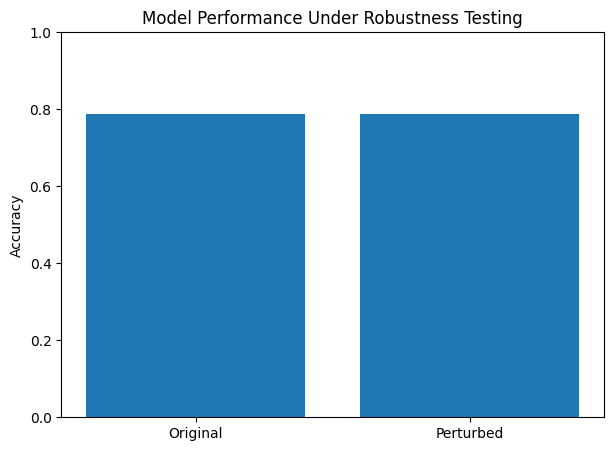

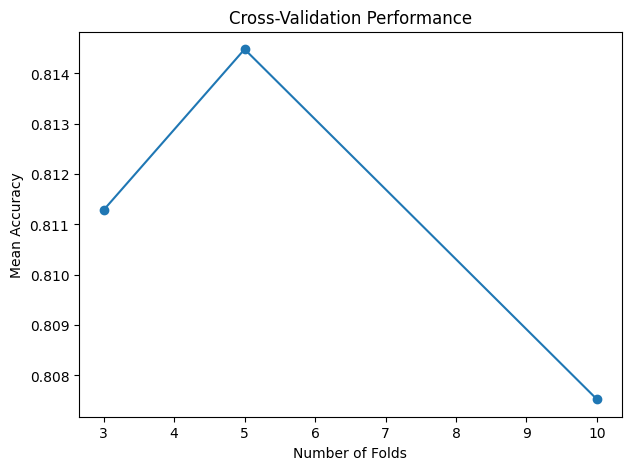

In [8]:
performance = pd.DataFrame({
    "Testing": ["Original", "Perturbed"],
    "Accuracy": [baseline["Accuracy"], adversarial_accuracy]
})

plt.figure(figsize=(7, 5))
plt.bar(performance["Testing"], performance["Accuracy"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Model Performance Under Robustness Testing")
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(cv_df["Folds"], cv_df["Mean Accuracy"], marker="o")
plt.xlabel("Number of Folds")
plt.ylabel("Mean Accuracy")
plt.title("Cross-Validation Performance")
plt.show()

In [9]:
failure_modes = [
    "Prediction changes after small input perturbations",
    "High-confidence predictions on unfamiliar synthetic inputs",
    "False positives and false negatives",
    "Performance variation across different data splits",
    "Potential differences in prediction errors across demographic groups"
]

recommendations = [
    "Use stratified cross-validation for reliable evaluation",
    "Collect more representative and diverse training samples",
    "Investigate false positives and false negatives separately",
    "Apply fairness evaluation and mitigation where appropriate",
    "Test model confidence and calibration",
    "Use realistic domain-validated adversarial and OOD samples",
    "Monitor model performance after deployment"
]

report = f"""
HEART DISEASE MODEL ROBUSTNESS TECHNICAL REPORT

Date: {datetime.now().strftime("%Y-%m-%d")}

1. EXPERIMENTAL SETUP

Dataset: Heart Disease Dataset (heart.csv)
Total Samples: {len(df)}
Features: {X.shape[1]}
Training Samples: {len(X_train)}
Testing Samples: {len(X_test)}
Model: Random Forest Classifier
Number of Estimators: 100
Train-Test Ratio: 80:20

2. BASELINE PERFORMANCE

Accuracy: {baseline['Accuracy']:.4f}
Precision: {baseline['Precision']:.4f}
Recall: {baseline['Recall']:.4f}
F1 Score: {baseline['F1 Score']:.4f}

3. ADVERSARIAL TESTING

Perturbed Accuracy: {adversarial_accuracy:.4f}
Prediction Flip Rate: {prediction_flip_rate:.4f}

4. OUT-OF-DISTRIBUTION TESTING

Normal Mean Confidence: {normal_confidence.mean():.4f}
OOD Mean Confidence: {ood_confidence.mean():.4f}
High Confidence OOD Samples: {int((ood_confidence >= 0.90).sum())}

5. CROSS-VALIDATION RESULTS

{cv_df.round(4).to_string(index=False)}

6. IDENTIFIED FAILURE MODES

{chr(10).join(failure_modes)}

7. RECOMMENDATIONS

{chr(10).join(recommendations)}

8. CONCLUSION

The model was evaluated using baseline testing, adversarial
perturbations, synthetic OOD samples and cross-validation.

The results help identify prediction instability, confidence
issues and possible generalization limitations.

Further validation using independent and representative
clinical datasets is required before real-world use.
"""

print(report)


HEART DISEASE MODEL ROBUSTNESS TECHNICAL REPORT

Date: 2026-10-30

1. EXPERIMENTAL SETUP

Dataset: Heart Disease Dataset (heart.csv)
Total Samples: 302
Features: 13
Training Samples: 241
Testing Samples: 61
Model: Random Forest Classifier
Number of Estimators: 100
Train-Test Ratio: 80:20

2. BASELINE PERFORMANCE

Accuracy: 0.7869
Precision: 0.7500
Recall: 0.9091
F1 Score: 0.8219

3. ADVERSARIAL TESTING

Perturbed Accuracy: 0.7869
Prediction Flip Rate: 0.0000

4. OUT-OF-DISTRIBUTION TESTING

Normal Mean Confidence: 0.7692
OOD Mean Confidence: 0.6962
High Confidence OOD Samples: 6

5. CROSS-VALIDATION RESULTS

 Folds  Mean Accuracy  Accuracy Variance  Standard Deviation
     3         0.8113             0.0020              0.0449
     5         0.8145             0.0020              0.0443
    10         0.8075             0.0047              0.0687

6. IDENTIFIED FAILURE MODES

Prediction changes after small input perturbations
High-confidence predictions on unfamiliar synthetic inputs

In [10]:
print("ROBUSTNESS TESTING SUMMARY")

print("\nBaseline Accuracy:", round(baseline["Accuracy"], 4))
print("Adversarial Accuracy:", round(adversarial_accuracy, 4))
print("Prediction Flip Rate:", round(prediction_flip_rate, 4))

print("\nNormal Confidence:", round(normal_confidence.mean(), 4))
print("OOD Confidence:", round(ood_confidence.mean(), 4))

print("\nCross-Validation Results:")
display(cv_df.round(4))

print("\nTechnical report generated successfully inside the notebook.")

ROBUSTNESS TESTING SUMMARY

Baseline Accuracy: 0.7869
Adversarial Accuracy: 0.7869
Prediction Flip Rate: 0.0

Normal Confidence: 0.7692
OOD Confidence: 0.6962

Cross-Validation Results:


,Folds,Mean Accuracy,Accuracy Variance,Standard Deviation
0,3,0.8113,0.0020,0.0449
1,5,0.8145,0.0020,0.0443
2,10,0.8075,0.0047,0.0687



Technical report generated successfully inside the notebook.
